[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AIforPhilanthropy/eduall/blob/main/traditionalAI_groupwork/02_decision_trees_random_forest.ipynb)

# EduAll — Decision Trees and Random Forests for Grant Allocation

**Input:** `data/EduAll_500_Applications_Dataset.csv`. There is no "selected / not selected" label in
this dataset — the foundation has not decided anything yet — so a decision tree or random forest cannot
be used the ordinary, supervised way (predicting a known outcome). Three different, genuinely
label-free uses of trees are developed instead:

1. **A decision tree (and then a random forest) that explains `financial_need_chf`** from the
   applicant's other characteristics. The point is not prediction for its own sake: the *splits* a tree
   chooses are themselves informative about which variables and which thresholds a committee should
   pay attention to when setting eligibility or priority rules.
2. **A random-forest-derived proximity (distance) matrix.** A forest trained on a real target still
   implicitly measures "how similar two applicants are", because two applicants that keep landing in the
   same leaf across hundreds of trees are, by the forest's own splits, alike in the respects that matter
   for need. That proximity is turned into a distance and used for clustering, exactly as in the
   unsupervised notebook, but driven entirely by the forest's splits rather than a hand-written metric.
3. **A tool that lets a student (not an algorithm) choose which variables matter and how much**, and
   fits a transparent tree/forest to visualise and allocate according to *their* stated priorities.

Runs standalone in Google Colab; no other files are required besides the CSV.

In [ ]:
# --- Get the data -------------------------------------------------------------------------------
# On Google Colab this cell downloads the course repository (data + notebooks) from GitHub and moves into this
# notebook's folder, so every data path below works as on the course computers. Locally it does nothing.
import os, pathlib, subprocess
REPO_URL = "https://github.com/AIforPhilanthropy/eduall.git"
NOTEBOOK_DIR = "traditionalAI_groupwork"          # this notebook's folder inside the repository
here = pathlib.Path.cwd()
if not any((p / "data" / "EduAll_500_Applications_Dataset.csv").exists() for p in [here, *here.parents]):
    if not pathlib.Path("/content/eduall").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/eduall"], check=True)
    os.chdir(pathlib.Path("/content/eduall") / NOTEBOOK_DIR)
print("working directory:", os.getcwd())

## 0. Setup

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

SEED = 42
np.random.seed(SEED)
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                      "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.width", 140)

## 1. Load the data

In [2]:
CSV_CANDIDATES = [
    pathlib.Path("../data/EduAll_500_Applications_Dataset.csv"),
    pathlib.Path("data/EduAll_500_Applications_Dataset.csv"),
    pathlib.Path("EduAll_500_Applications_Dataset.csv"),
]
csv_path = next((p for p in CSV_CANDIDATES if p.exists()), None)
if csv_path is None:
    try:
        from google.colab import files
        print("CSV not found next to the notebook -- please upload EduAll_500_Applications_Dataset.csv")
        uploaded = files.upload()
        csv_path = pathlib.Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            "Could not find EduAll_500_Applications_Dataset.csv. "
            "Place it at ../data/ relative to this notebook, or upload it.")

raw = pd.read_csv(csv_path, keep_default_na=False)
print(raw.shape)
raw.head(3)

(500, 44)


,student_id,application_date,age,gender,country_origin,gni_tier,geographic_region,dependent_children,study_level,university,...,risk_housing_insecurity,risk_family_emergency,risk_language_barrier,risk_parent_student,risk_undocumented_status,resilience_volunteer_experience,resilience_work_experience,resilience_leadership_role,resilience_community_engagement,resilience_overcame_adversity
0,STU000001,7/24/26,21,Male,Indonesia,2,Southeast Asia,0,Bachelor's,University of Geneva,...,1,0,0,0,0,0,1,1,1,0
1,STU000002,8/18/26,27,Non-binary,Pakistan,1,South Asia,0,Master's,University of Lausanne,...,0,0,0,0,0,0,1,0,0,1
2,STU000003,7/17/26,27,Male,Vietnam,2,Southeast Asia,0,Master's,University of Geneva,...,1,0,0,0,0,0,1,0,0,0


## 2. Features

The same kind of variables as in the clustering notebook (financial, academic, legal, declared
circumstances), but trees need a numeric matrix, so categorical variables are one-hot encoded here
rather than compared directly.

In [3]:
REQUIRED = {"Bachelor's": 40, "Master's": 12, "Doctoral": 12}
RISK_COLS = ["risk_first_generation", "risk_refugee_asylum", "risk_disability", "risk_housing_insecurity",
             "risk_family_emergency", "risk_language_barrier", "risk_parent_student",
             "risk_undocumented_status"]
RESIL_COLS = ["resilience_volunteer_experience", "resilience_work_experience", "resilience_leadership_role",
              "resilience_community_engagement", "resilience_overcame_adversity"]

df = raw.copy()
df["progress_ratio"] = (df.courses_completed / df.study_level.map(REQUIRED)).clip(0, 1)
df["risk_count"] = df[RISK_COLS].sum(axis=1)
df["resil_count"] = df[RESIL_COLS].sum(axis=1)
df = df.set_index("student_id")

NUM_FEATS = ["age", "gpa", "savings_chf", "progress_ratio", "risk_count", "resil_count",
             "dependent_children", "publications"] + RISK_COLS + RESIL_COLS
CAT_FEATS = ["study_level", "gni_tier", "geographic_region", "residency_permit", "study_mode",
             "academic_standing", "has_external_scholarship"]
TARGET = "financial_need_chf"

Xnum = df[NUM_FEATS].astype(float)
Xcat = pd.get_dummies(df[CAT_FEATS].astype(str), prefix=CAT_FEATS)
Xfull = pd.concat([Xnum, Xcat], axis=1)
y = df[TARGET].astype(float)
print(Xfull.shape, "features;  target: monthly financial need (CHF)")

(500, 45) features;  target: monthly financial need (CHF)


## 3. A single decision tree, and what its splits say

A shallow tree (`max_depth=3`) is deliberately used first: deep trees predict better but a human cannot
read their splits, and here the *splits themselves* are the point, not the prediction. We hold out 20%
of applicants to report an honest $R^2$, but the tree used for the picture and for the splits is refit on
all 500 (a committee wants a rule that reflects everyone, not one that was never shown 20% of the pool).

held-out R^2 (max_depth=3): 0.59


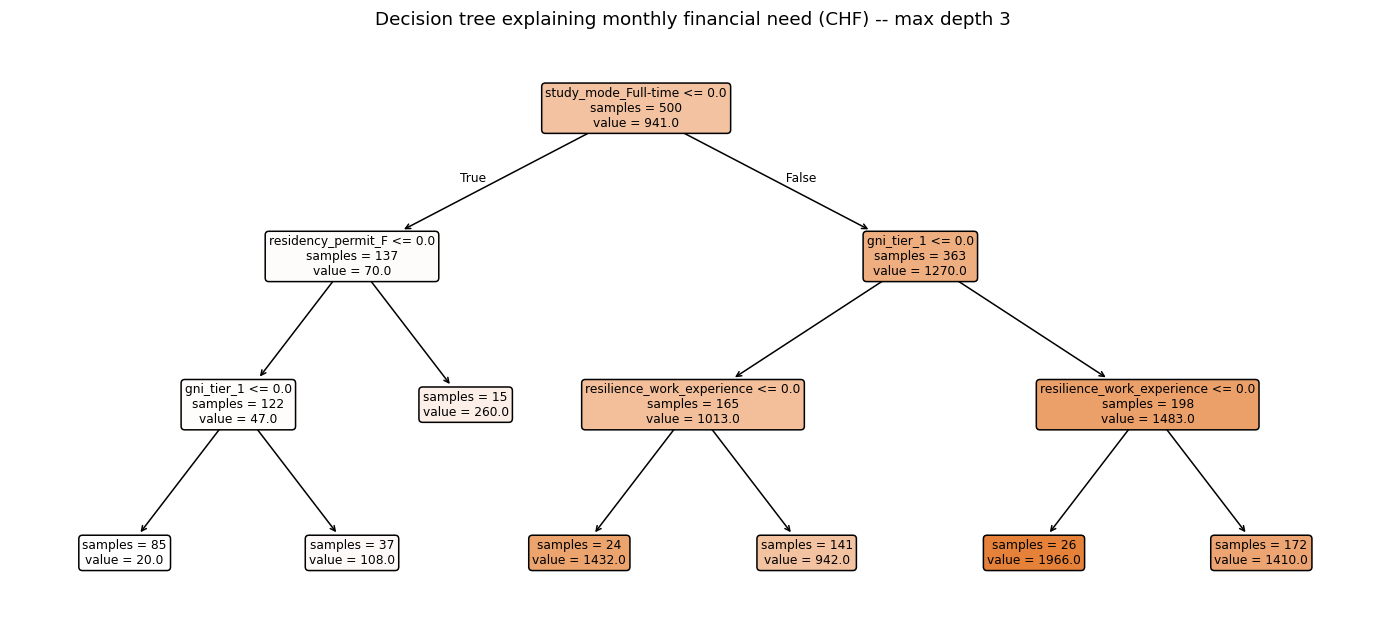

In [4]:
Xtr, Xte, ytr, yte = train_test_split(Xfull, y, test_size=0.2, random_state=SEED)
tree_cv = DecisionTreeRegressor(max_depth=3, min_samples_leaf=15, random_state=SEED).fit(Xtr, ytr)
print(f"held-out R^2 (max_depth=3): {r2_score(yte, tree_cv.predict(Xte)):.2f}")

tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=15, random_state=SEED).fit(Xfull, y)
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree, feature_names=Xfull.columns, filled=True, rounded=True, fontsize=8, ax=ax,
          impurity=False, precision=0)
ax.set_title("Decision tree explaining monthly financial need (CHF) -- max depth 3")
plt.show()

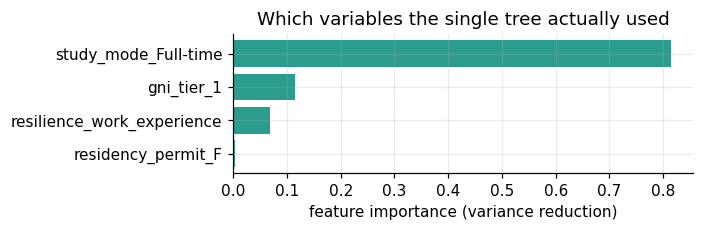

In [5]:
imp = pd.Series(tree.feature_importances_, index=Xfull.columns).sort_values(ascending=False)
imp = imp[imp > 0]
fig, ax = plt.subplots(figsize=(6.5, max(2.2, 0.28 * len(imp))))
ax.barh(imp.index[::-1], imp.values[::-1], color="#2a9d8f")
ax.set_xlabel("feature importance (variance reduction)")
ax.set_title("Which variables the single tree actually used")
plt.tight_layout(); plt.show()

The first split alone tells a committee what dominates monthly need in this pool before any other rule is applied: read the root node's feature and threshold in the printed tree above, and compare it with the importance ranking -- a variable can matter a great deal at one specific split (e.g. separating a `study_mode` group) without topping the overall importance ranking, which aggregates many splits.

## 4. Random forest: a more stable ranking of what matters

A single tree's splits can be an accident of a few borderline applicants. A random forest averages
hundreds of trees, each grown on a bootstrap sample with a random subset of features considered at every
split, which makes the *ranking* of important variables much more stable (and usually improves
predictive accuracy).

held-out R^2: 0.61   OOB R^2: 0.57


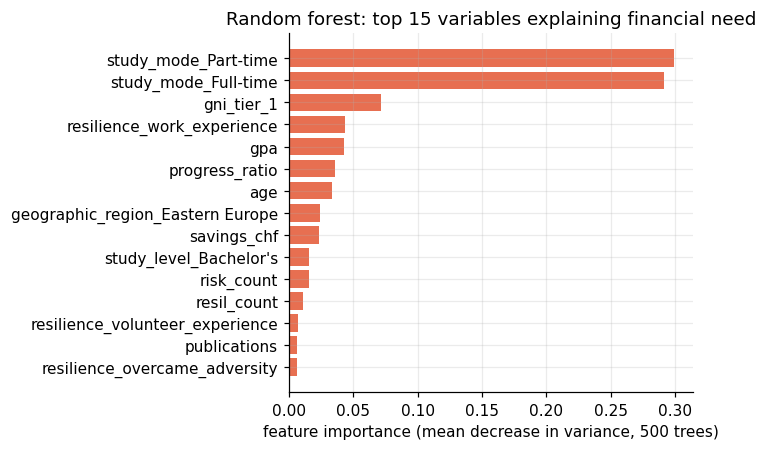

In [6]:
rf_cv = RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=SEED, n_jobs=-1,
                               oob_score=True).fit(Xtr, ytr)
print(f"held-out R^2: {r2_score(yte, rf_cv.predict(Xte)):.2f}   OOB R^2: {rf_cv.oob_score_:.2f}")

rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=SEED, n_jobs=-1,
                            oob_score=True).fit(Xfull, y)
imp_rf = pd.Series(rf.feature_importances_, index=Xfull.columns).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(imp_rf.index[::-1], imp_rf.values[::-1], color="#e76f51")
ax.set_xlabel("feature importance (mean decrease in variance, 500 trees)")
ax.set_title("Random forest: top 15 variables explaining financial need")
plt.tight_layout(); plt.show()

In [7]:
comparison = pd.DataFrame({"single tree": pd.Series(tree.feature_importances_, index=Xfull.columns),
                            "random forest": pd.Series(rf.feature_importances_, index=Xfull.columns)})
comparison = comparison[(comparison["single tree"] > 0) | (comparison["random forest"] > 0.01)]
comparison.sort_values("random forest", ascending=False).round(3)

,single tree,random forest
study_mode_Part-time,0.000,0.299
study_mode_Full-time,0.815,0.291
gni_tier_1,0.114,0.071
resilience_work_experience,0.068,0.044
gpa,0.000,0.042
progress_ratio,0.000,0.036
age,0.000,0.033
geographic_region_Eastern Europe,0.000,0.024
savings_chf,0.000,0.023
study_level_Bachelor's,0.000,0.016


The forest's ranking is the more trustworthy one of the two for *deciding what to measure and weight* in an allocation rule, precisely because it does not depend on which few applicants happened to sit near a single tree's split points.

## 5. A random-forest proximity (distance) matrix

This is the part the brief specifically asks for: a random forest can define a similarity between two
applicants without ever training on a "same group / different group" label. The trick (Breiman, 2001) is
structural, not statistical: pass every applicant down every one of the forest's trees, and record, for
each pair, the *fraction of trees in which they land in the same terminal leaf*. Two applicants who are
alike in every respect the forest's splits care about for predicting need will co-occur in the same leaf
far more often than two applicants who are not -- regardless of whether their raw need values happen to
be close. The forest above (trained on `financial_need_chf`) is reused; its splits already encode what
"similar, for the purpose of need" means.

In [8]:
leaf_ids = rf.apply(Xfull)                       # (n_applicants, n_trees): leaf index per tree
n = leaf_ids.shape[0]
proximity = np.zeros((n, n))
for t in range(leaf_ids.shape[1]):
    col = leaf_ids[:, t]
    proximity += (col[:, None] == col[None, :])
proximity /= leaf_ids.shape[1]
rf_distance = 1 - proximity
np.fill_diagonal(rf_distance, 0)
print("RF distance matrix:", rf_distance.shape, " range:", rf_distance.min().round(3), "-", rf_distance.max().round(3))

RF distance matrix: (500, 500)  range: 0.0 - 1.0


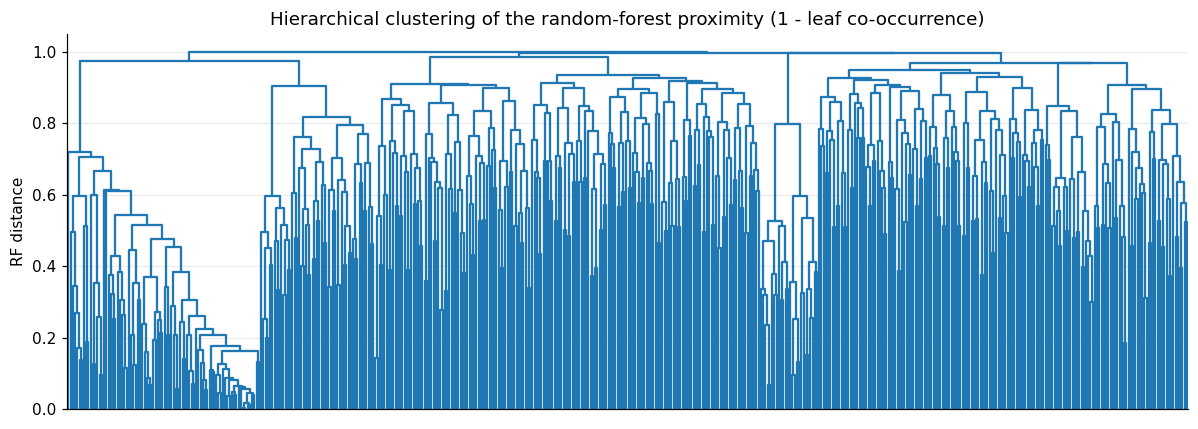

In [9]:
condensed = squareform(rf_distance, checks=False)
Z = linkage(condensed, method="average")
fig, ax = plt.subplots(figsize=(11, 4))
dendrogram(Z, no_labels=True, color_threshold=0, ax=ax)
ax.set_title("Hierarchical clustering of the random-forest proximity (1 - leaf co-occurrence)")
ax.set_ylabel("RF distance")
plt.tight_layout(); plt.show()

In [10]:
K_CLUSTERS = 6
rf_cluster = pd.Series(fcluster(Z, t=K_CLUSTERS, criterion="maxclust"), index=Xfull.index, name="rf_cluster")
df["rf_cluster"] = rf_cluster
df.groupby("rf_cluster").agg(n=("age", "size"), mean_need=("financial_need_chf", "mean"),
                              mean_gpa=("gpa", "mean"), pct_tier1=("gni_tier", lambda s: (s == 1).mean() * 100),
                              pct_at_risk=("academic_standing", lambda s: (s == "At Risk").mean() * 100)
                              ).round(1).sort_values("mean_need", ascending=False)

,n,mean_need,mean_gpa,pct_tier1,pct_at_risk
rf_cluster,,,,,
5,26,1966.1,3.0,100.0,19.2
4,102,1520.6,3.1,100.0,8.8
3,70,1248.6,2.8,100.0,24.3
6,165,1013.5,3.1,0.0,10.9
2,51,154.9,2.9,100.0,21.6
1,86,19.8,2.9,0.0,24.4


### From RF clusters to money

The same floor-plus-proportional-need logic as the unsupervised notebook is applied here, so the two
independent methods (hand-written Gower distance + Leiden vs. random-forest leaf co-occurrence +
hierarchical clustering) can be compared on common ground: same budget, same per-level caps, same
reach-floor philosophy, different machinery for deciding who is "alike".

In [11]:
BUDGET = 500_000
CAP = {"Bachelor's": 8_000, "Master's": 6_500, "Doctoral": 5_000}
FLOOR_SHARE = 0.10

df["request_chf"] = np.minimum(df.financial_need_chf * 12, df.study_level.map(CAP))
elig = df.request_chf > 0
creq = df.loc[elig].groupby("rf_cluster").request_chf.sum()
floor_pool, need_pool = BUDGET * FLOOR_SHARE, BUDGET * (1 - FLOOR_SHARE)
envelope = (floor_pool / K_CLUSTERS) + need_pool * creq / creq.sum()

award = pd.Series(0.0, index=df.index)
for c, env in envelope.items():
    pool = df.index[(df.rf_cluster == c) & elig]
    order = df.loc[pool, "request_chf"].sort_values(ascending=False).index
    left = env
    for sid in order:
        g = min(df.at[sid, "request_chf"], left)
        award[sid] = g; left -= g
        if left <= 0:
            break
df["award_chf"] = award
print(f"total awarded: CHF {award.sum():,.0f} of CHF {BUDGET:,.0f}")
print(f"applicants funded: {(award > 0).sum()} of {elig.sum()} eligible")
df.groupby("rf_cluster").agg(total_request=("request_chf", "sum"), total_award=("award_chf", "sum"),
                              n_funded=("award_chf", lambda s: (s > 0).sum())).round(0)

total awarded: CHF 500,000 of CHF 500,000
applicants funded: 69 of 361 eligible


,total_request,total_award,n_funded
rf_cluster,,,
1,17708,11762.0,2
2,92280,26201.0,4
3,541640,113208.0,15
4,622020,128772.0,20
5,187000,44541.0,6
6,863440,175516.0,22


## 6. Choose your own priorities

Everything so far lets an *algorithm's* split points decide what matters. This section inverts that: a
student states, in plain weights, how much they personally care about each of a menu of criteria
(`0` = ignore it entirely). A decision tree and a random forest are then fit to **explain that personal
priority score from the applicants' raw variables** -- so the result is not a black box: the tree's
splits are a readable summary of what "a grant-maker with these weights" ends up actually rewarding, in
terms a committee could put in a policy document. The budget is then allocated by the student's own
score directly, ranked and capped exactly as before.

Every variable below is pre-oriented so that **a higher value always means higher priority** (e.g.
`savings_chf` is inverted, since *less* saved should mean *more* priority for a need-based grant);
set a weight to `0` to drop a criterion entirely.

In [12]:
def minmax(s):
    s = s.astype(float)
    rng = s.max() - s.min()
    return (s - s.min()) / rng if rng > 0 else s * 0

PRIORITY_MENU = {
    "financial_need":   minmax(df.financial_need_chf),
    "low_savings":      1 - minmax(df.savings_chf),
    "low_family_income": 1 - minmax(df.family_income_chf),
    "academic_merit":   minmax(df.gpa),
    "academic_progress": minmax(df.progress_ratio),
    "risk_factors":     minmax(df.risk_count),
    "resilience_factors": minmax(df.resil_count),
    "first_generation": df.risk_first_generation.astype(float),
    "refugee_or_asylum": df.risk_refugee_asylum.astype(float),
    "disability":        df.risk_disability.astype(float),
    "student_parent":    df.risk_parent_student.astype(float),
    "tier1_country":     (df.gni_tier == 1).astype(float),
    "has_other_scholarship_already": 1 - df.has_external_scholarship.astype(float),
}
pd.DataFrame(PRIORITY_MENU).describe().loc[["mean", "std", "min", "max"]].round(2).T

,mean,std,min,max
financial_need,0.39,0.32,0.0,1.0
low_savings,0.79,0.31,0.0,1.0
low_family_income,0.85,0.17,0.0,1.0
academic_merit,0.49,0.23,0.0,1.0
academic_progress,0.42,0.22,0.0,1.0
risk_factors,0.26,0.20,0.0,1.0
resilience_factors,0.53,0.24,0.0,1.0
first_generation,0.56,0.50,0.0,1.0
refugee_or_asylum,0.05,0.22,0.0,1.0
disability,0.09,0.29,0.0,1.0


In [13]:
def composite_score(weights: dict) -> pd.Series:
    """weights: {criterion name (from PRIORITY_MENU): non-negative importance}. Unlisted criteria get 0."""
    w = pd.Series({k: weights.get(k, 0.0) for k in PRIORITY_MENU})
    if w.sum() == 0:
        raise ValueError("At least one weight must be > 0")
    w = w / w.sum()
    M = pd.DataFrame(PRIORITY_MENU)
    return (M * w).sum(axis=1)

def explain_and_allocate(weights: dict, label: str, budget=500_000, cap=None, show=True):
    cap = cap or {"Bachelor's": 8_000, "Master's": 6_500, "Doctoral": 5_000}
    score = composite_score(weights)
    request = np.minimum(df.financial_need_chf * 12, df.study_level.map(cap))

    pol_tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=15, random_state=SEED).fit(Xfull, score)
    pol_rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED,
                                    n_jobs=-1).fit(Xfull, score)

    order = score[request > 0].sort_values(ascending=False).index
    award = pd.Series(0.0, index=df.index)
    left = budget
    for sid in order:
        g = min(request.at[sid], left)
        award[sid] = g; left -= g
        if left <= 0:
            break

    if show:
        fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})
        plot_tree(pol_tree, feature_names=Xfull.columns, filled=True, rounded=True, fontsize=7,
                  ax=axes[0], impurity=False, precision=2)
        axes[0].set_title(f"{label}: tree explaining the composite score")
        imp = pd.Series(pol_rf.feature_importances_, index=Xfull.columns).sort_values(ascending=False).head(10)
        axes[1].barh(imp.index[::-1], imp.values[::-1], color="#6d597a")
        axes[1].set_title("Top variables (random forest)")
        plt.tight_layout(); plt.show()
        print(f"{label}: CHF {award.sum():,.0f} awarded to {(award > 0).sum()} applicants "
              f"(of {(request > 0).sum()} with a positive request)")
    return award, score

### Three example grant-makers, and then your own

Three illustrative weight profiles first, to show the tool working end to end; edit the fourth cell
(`my_weights`) with your own numbers and rerun it -- that is the point of this section.

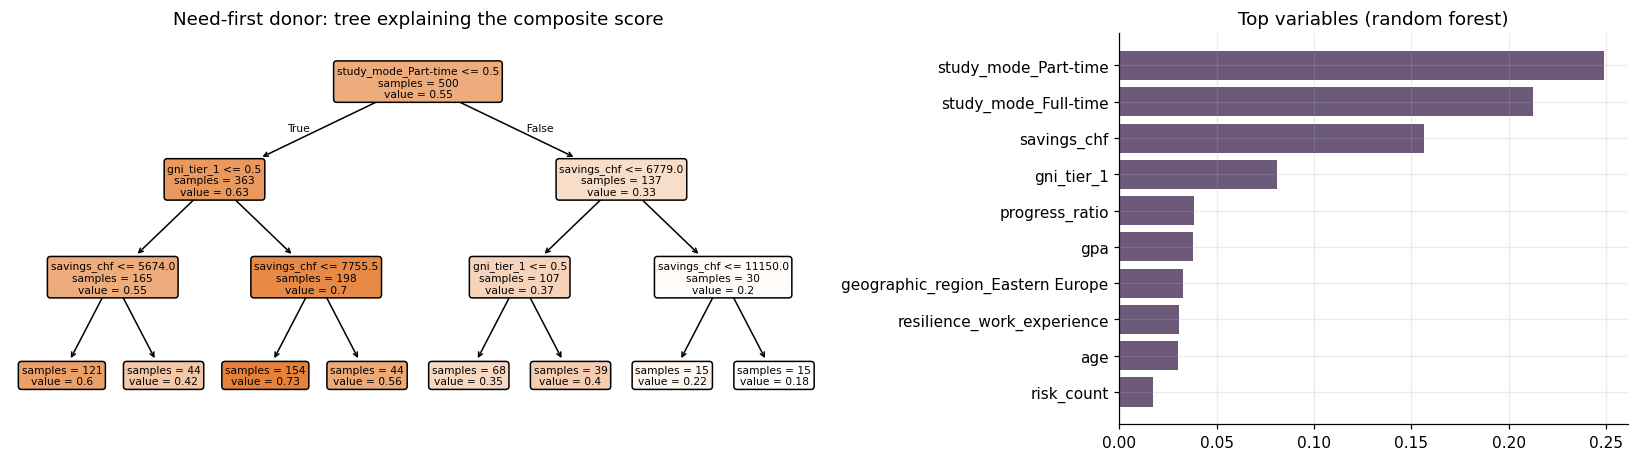

Need-first donor: CHF 500,000 awarded to 73 applicants (of 361 with a positive request)


In [14]:
need_first = {"financial_need": 5, "low_savings": 2, "low_family_income": 1}
merit_and_resilience = {"financial_need": 2, "academic_merit": 2, "academic_progress": 1,
                         "resilience_factors": 2, "risk_factors": 1}
equity_focused = {"financial_need": 1, "first_generation": 2, "refugee_or_asylum": 2,
                   "disability": 2, "student_parent": 2, "tier1_country": 2}

award_need, score_need = explain_and_allocate(need_first, "Need-first donor")

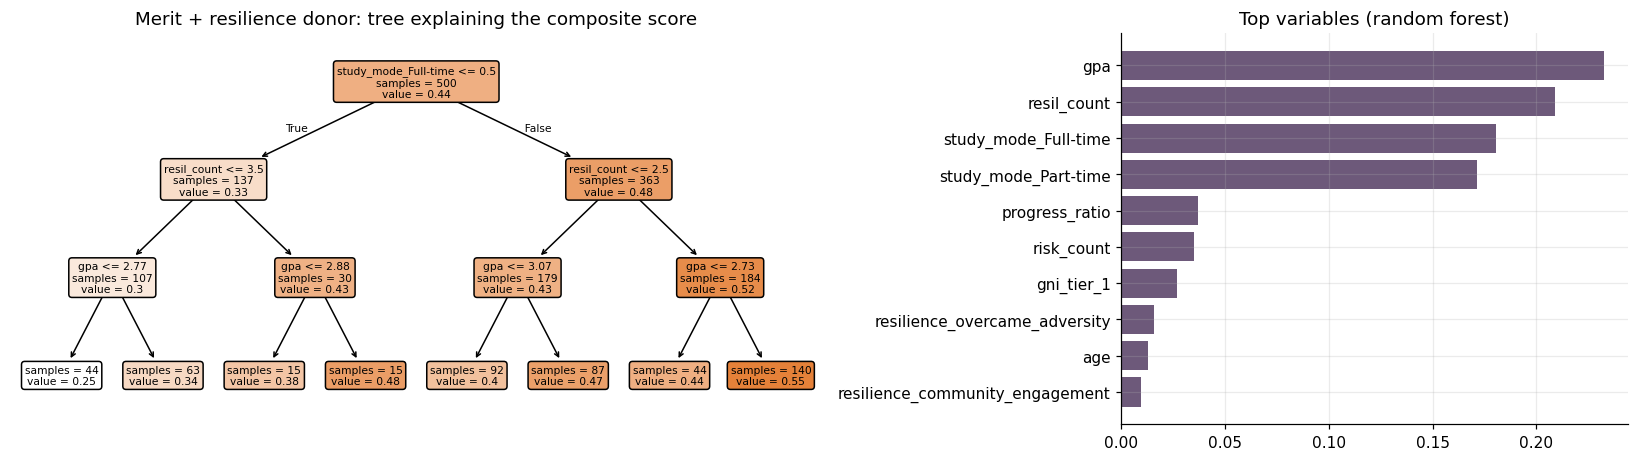

Merit + resilience donor: CHF 500,000 awarded to 77 applicants (of 361 with a positive request)


In [15]:
award_merit, score_merit = explain_and_allocate(merit_and_resilience, "Merit + resilience donor")

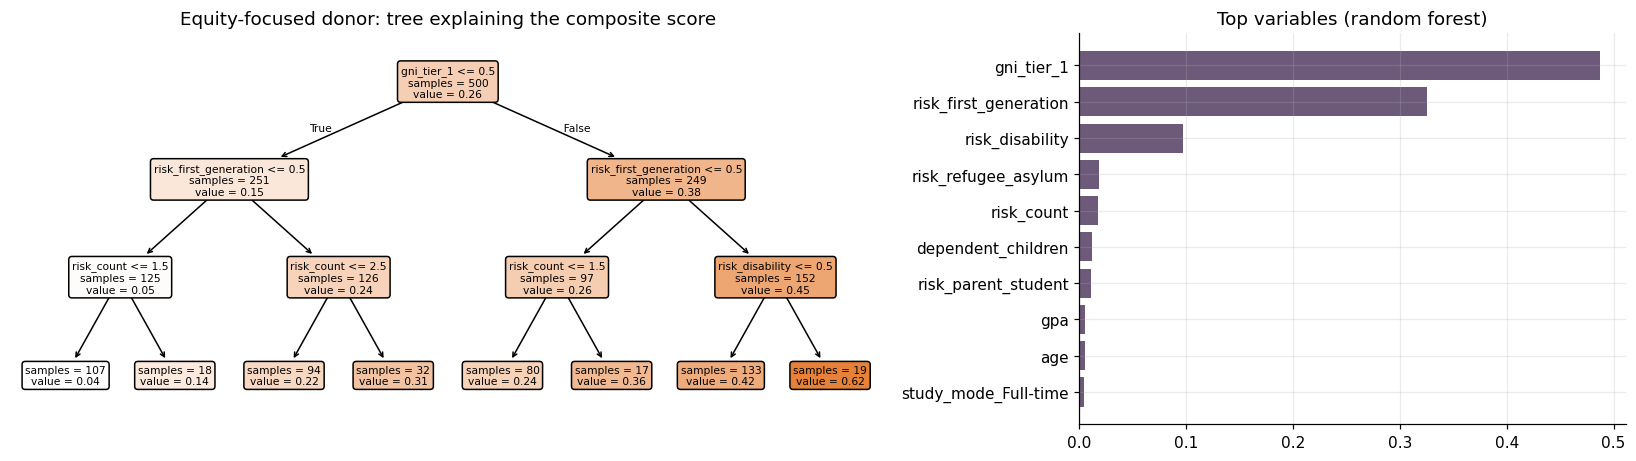

Equity-focused donor: CHF 500,000 awarded to 75 applicants (of 361 with a positive request)


In [16]:
award_equity, score_equity = explain_and_allocate(equity_focused, "Equity-focused donor")

In [17]:
overlap = pd.DataFrame({"need-first": award_need > 0, "merit+resilience": award_merit > 0,
                        "equity-focused": award_equity > 0})
print("How many applicants each pair of donor profiles agree on funding (out of 500):")
(overlap.T @ overlap).astype(int)

How many applicants each pair of donor profiles agree on funding (out of 500):


,need-first,merit+resilience,equity-focused
need-first,1,1,1
merit+resilience,1,1,1
equity-focused,1,1,1


The three profiles disagree about *who* gets funded far more than they disagree about *how much money is spent in total* (all three exhaust the same CHF 500,000). That gap between consensus on the budget and disagreement on individuals is exactly the kind of thing a committee should see before adopting any one weighting as the official rule.

### Your turn

Edit the weights below (any non-negative numbers; `0` or omitted = ignored) and rerun.

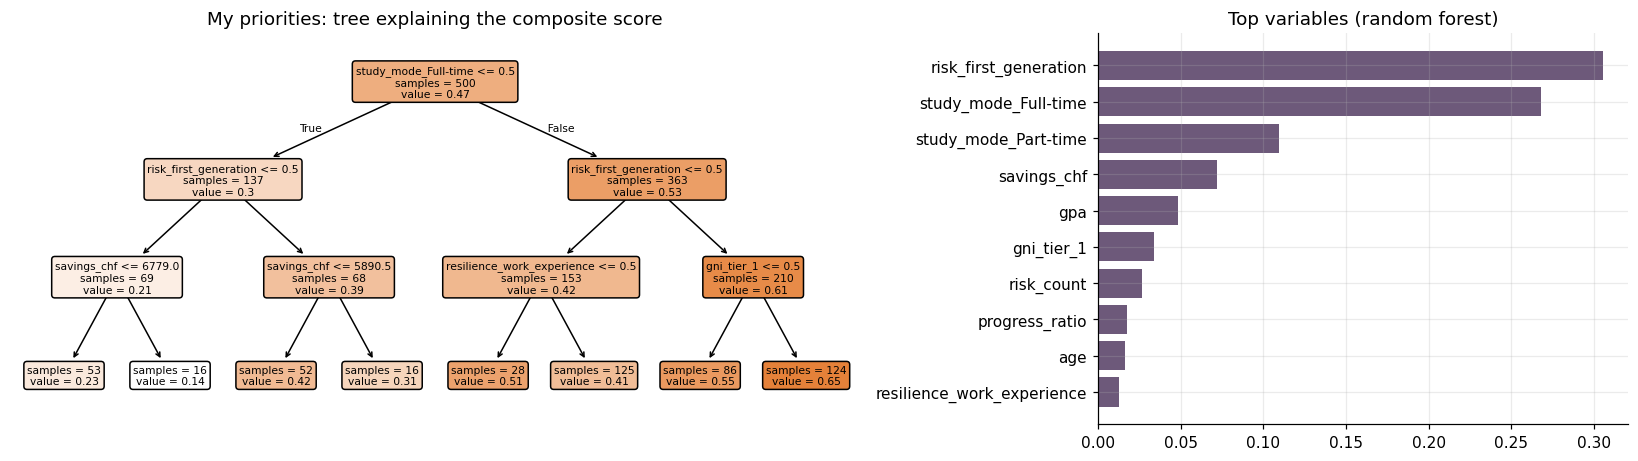

My priorities: CHF 500,000 awarded to 75 applicants (of 361 with a positive request)


In [18]:
my_weights = {
    "financial_need": 3,
    "low_savings": 1,
    "academic_merit": 1,
    "risk_factors": 1,
    "first_generation": 1,
    # add or remove any criterion from PRIORITY_MENU above, with your own weight
}
my_award, my_score = explain_and_allocate(my_weights, "My priorities")

## 7. Summary

* A single shallow tree makes a committee's eligibility logic legible: its splits can be read out loud
  as a rule. A forest is more reliable for ranking *which variables* matter, because it is not swayed by
  a handful of borderline applicants the way one tree's splits can be.
* A forest's leaf co-occurrence across hundreds of trees is a genuine, label-free distance metric --
  it clusters applicants by what the forest's splits treat as relevant to need, not by an arbitrary
  choice of metric.
* None of this removes the value judgement from allocation. It relocates it to a place where it is
  visible and adjustable: the weights in Section 6, or the floor-share and cap choices reused from the
  unsupervised notebook. The role of the trees and forests is to make the *consequences* of a stated
  priority legible and to make *why* an applicant was or was not funded traceable to specific variables
  and thresholds -- not to supply the priority itself.